# Regressão linear com várias variáveis: preço de casas na Califórnia

## Objetivos

- Estender o pipeline do 2.6 (`nn.Linear`, `nn.MSELoss`, `optim.SGD`, `train_epoch`/`validate_epoch`) de **1 para 8 variáveis de entrada**: o modelo passa a ser `nn.Linear(8, 1)`.
- Dividir os dados em **treino, validação e teste** (70/15/15) e padronizar entradas e saída usando só o treino.
- Avaliar o RMSE no teste **em dólares**, comparando com um baseline que sempre prevê o preço médio do treino.
- Interpretar os pesos aprendidos.

Com 8 entradas, o modelo é

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8$$

em que $w_0$ é o bias (`model.bias`) e $w_1,\dots,w_8$ são os pesos (`model.weight`, shape (1, 8)).

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

O *California Housing* (censo de 1990) vem no scikit-learn. Cada linha é um **quarteirão** (*block group*), não uma casa. A saída `y` é o valor mediano das casas do quarteirão, em **centenas de milhares de dólares** (3,5 = US$ 350.000).

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # 20.640 quarteirões, 8 variáveis

print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### Significado das variáveis

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana das famílias do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana das casas (anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | população do quarteirão |
| `AveOccup` | média de moradores por domicílio |
| `Latitude` | latitude (quanto maior, mais ao norte) |
| `Longitude` | longitude (quanto mais negativa, mais a oeste, perto do litoral) |
| **`MedHouseVal` (saída $y$)** | valor mediano das casas, em centenas de milhares de dólares |

In [3]:
df = pd.concat([X, y], axis=1)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Pontos a observar no `describe()`: `AveRooms`, `AveBedrms` e `AveOccup` têm máximos absurdos (dezenas ou centenas de cômodos ou moradores por domicílio), o que indica moradias atípicas. Além disso, o preço máximo é 5,0 (US$ 500.000), valor em que o dataset **trunca** os preços mais altos.

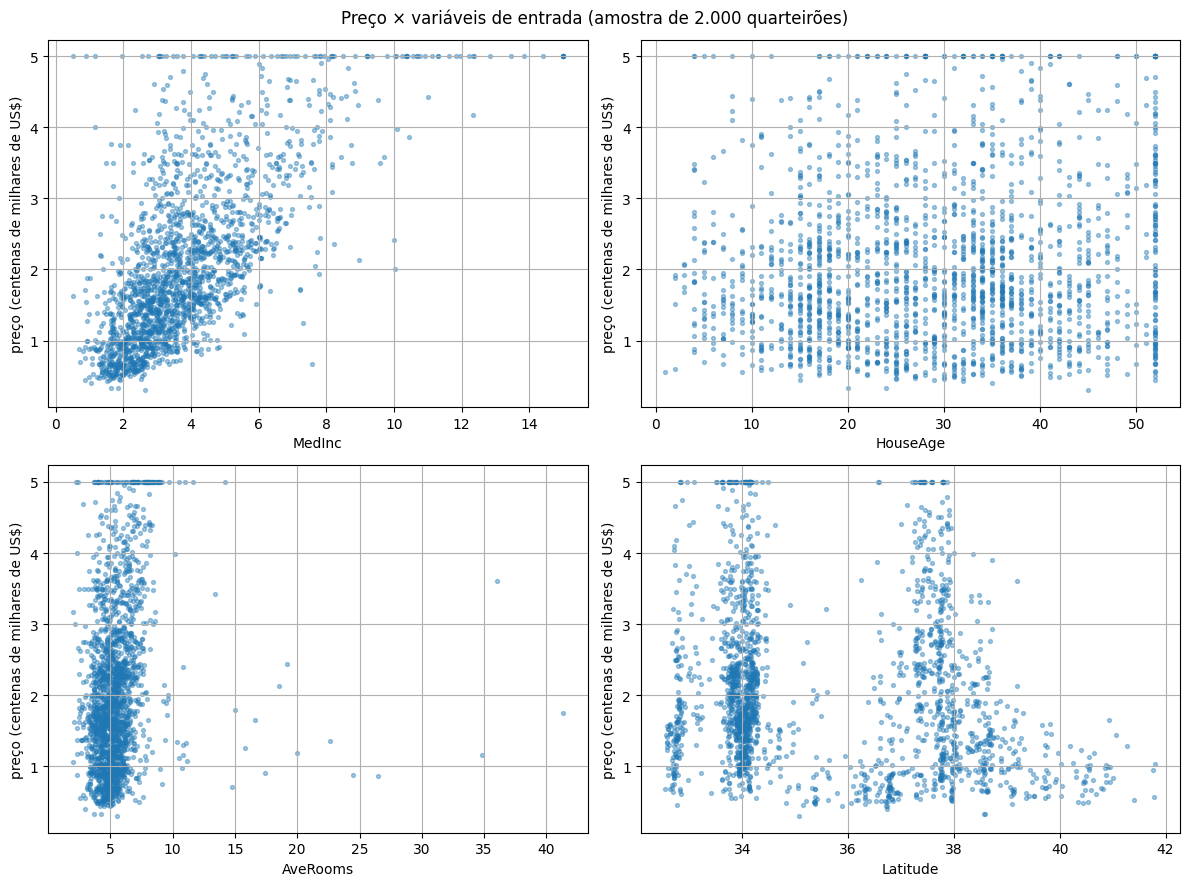

In [4]:
# gráficos de dispersão: 4 variáveis contra o preço
amostra = df.sample(2000, random_state=42)

fig, eixos = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(eixos.ravel(), ['MedInc', 'HouseAge', 'AveRooms', 'Latitude']):
    ax.scatter(amostra[col], amostra['MedHouseVal'], s=8, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel('preço (centenas de milhares de US$)')
    ax.grid(True)
plt.suptitle('Preço × variáveis de entrada (amostra de 2.000 quarteirões)')
plt.tight_layout()
plt.show()

A renda mediana (`MedInc`) tem a relação mais clara e quase linear com o preço. Já `HouseAge` e `AveRooms` mostram relações fracas. A latitude mostra faixas: preços altos concentrados em certas latitudes.

### Treino × validação × teste

Dividimos em 70% treino, 15% validação e 15% teste, em duas etapas, com `random_state` fixo:

- **treino**: ajusta os parâmetros (pesos e bias);
- **validação**: acompanha o custo durante o treino e ajuda a escolher hiperparâmetros (como o `lr`);
- **teste**: usado **uma única vez, no final**, para estimar o erro em dados novos.

In [5]:
X_raw = X.to_numpy()
y_raw = y.to_numpy().reshape(-1, 1)

# 1ª divisão
X_train_raw, X_tmp, y_train_raw, y_tmp = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=42)

# 2ª divisão
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=42)

print('treino:', X_train_raw.shape, ' validação:', X_val_raw.shape, ' teste:', X_test_raw.shape)

treino: (14448, 8)  validação: (3096, 8)  teste: (3096, 8)


### Padronização

As variáveis têm escalas muito diferentes (`Population` na casa dos milhares, `MedInc` entre 0 e 15, `Latitude` perto de 35). Padronizamos cada coluna (z-score) com o `StandardScaler`. A saída $y$ também é padronizada, com um `StandardScaler` próprio.

In [6]:
x_scaler = StandardScaler().fit(X_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

def para_tensor(a):
    return torch.from_numpy(a).float()

x_train = para_tensor(x_scaler.transform(X_train_raw))
y_train = para_tensor(y_scaler.transform(y_train_raw))
x_val   = para_tensor(x_scaler.transform(X_val_raw))
y_val   = para_tensor(y_scaler.transform(y_val_raw))
x_test  = para_tensor(x_scaler.transform(X_test_raw))
y_test  = para_tensor(y_scaler.transform(y_test_raw))

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('médias do treino padronizado (devem ser ~0):', x_train.mean(dim=0).numpy().round(3))
print('desvios do treino padronizado (devem ser ~1):', x_train.std(dim=0).numpy().round(3))

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
médias do treino padronizado (devem ser ~0): [-0. -0.  0.  0.  0. -0. -0.  0.]
desvios do treino padronizado (devem ser ~1): [1. 1. 1. 1. 1. 1. 1. 1.]


## Modelo

`nn.Linear(8, 1)` recebe 8 entradas e devolve 1 saída: `model.weight` tem shape (1, 8) (um peso por variável) e `model.bias` tem shape (1,).

In [7]:
model = nn.Linear(8, 1)
print('weight:', model.weight.shape, ' bias:', model.bias.shape)
print('número de parâmetros:', sum(p.numel() for p in model.parameters()))

weight: torch.Size([1, 8])  bias: torch.Size([1])
número de parâmetros: 9


## Treinamento

### Função de custo e otimizador

Os mesmos do 2.6. O gradiente descendente usa todo o conjunto de treino em cada época (aqui, 14.448 amostras de uma vez). Com as entradas padronizadas, `lr = 0.2`.

In [8]:
lr = 0.2
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

### Funções de treino e de validação

In [9]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

In [10]:
n_epochs = 500
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 50 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch[50/500], Train Loss: 0.3938, Val Loss: 0.4065
Epoch[100/500], Train Loss: 0.3908, Val Loss: 0.4039
Epoch[150/500], Train Loss: 0.3907, Val Loss: 0.4038
Epoch[200/500], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[250/500], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[300/500], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[350/500], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[400/500], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[450/500], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[500/500], Train Loss: 0.3907, Val Loss: 0.4037


### Curvas de custo de treino e de validação

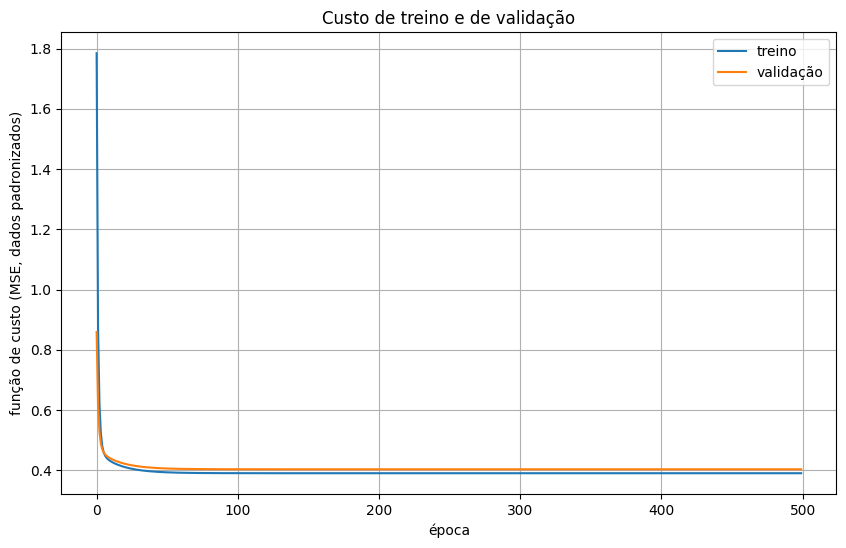

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

As duas curvas caem juntas e se estabilizam em valores próximos. Isso indica que o modelo **não está em overfitting**.

Como verificação, comparamos os parâmetros treinados com a solução analítica de mínimos quadrados, que é o ótimo para o treino:

In [12]:
# solução
X_b = np.hstack([np.ones((x_train.shape[0], 1)), x_train.numpy()])
theta, *_ = np.linalg.lstsq(X_b, y_train.numpy(), rcond=None)

print('bias   (SGD, analítico):', model.bias.item(), theta[0, 0])
print('pesos  (SGD):', model.weight.detach().numpy().ravel().round(4))
print('pesos  (analítico):', theta[1:].ravel().round(4))

bias   (SGD, analítico): 1.1933095400706861e-08 3.719153260082818e-09
pesos  (SGD): [ 0.7337  0.1055 -0.2588  0.301  -0.0008 -0.036  -0.7723 -0.7504]
pesos  (analítico): [ 0.7337  0.1055 -0.2588  0.301  -0.0008 -0.036  -0.7723 -0.7505]


## Avaliação no teste

O custo padronizado é difícil de interpretar. Levamos as previsões de volta à escala original com `y_scaler.inverse_transform` e multiplicamos por 100.000 (a unidade de $y$ é centenas de milhares de dólares).

In [13]:
FATOR = 100000

model.eval()
with torch.no_grad():
    y_test_pred_scaled = model(x_test)

y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled.numpy())

# RMSE
rmse_modelo = np.sqrt(np.mean((y_test_pred - y_test_raw) ** 2)) * FATOR

# baseline
y_base = np.full_like(y_test_raw, y_train_raw.mean())
rmse_baseline = np.sqrt(np.mean((y_base - y_test_raw) ** 2)) * FATOR

print(f'RMSE do modelo no teste:   US$ {rmse_modelo:,.0f}')
print(f'RMSE do baseline (média):  US$ {rmse_baseline:,.0f}')
print(f'redução do erro:           {100 * (1 - rmse_modelo / rmse_baseline):.1f}%')
print(f'preço médio no treino:     US$ {y_train_raw.mean() * FATOR:,.0f}')

RMSE do modelo no teste:   US$ 72,129
RMSE do baseline (média):  US$ 114,992
redução do erro:           37.3%
preço médio no treino:     US$ 206,924


## Pesos aprendidos

Os pesos estão na escala padronizada: cada peso diz quanto o preço previsto (em desvios padrão) muda quando aquela variável aumenta **1 desvio padrão**, mantendo as outras fixas.

Latitude     -0.772
Longitude    -0.750
AveRooms     -0.259
AveOccup     -0.036
Population   -0.001
HouseAge      0.106
AveBedrms     0.301
MedInc        0.734
dtype: float32
bias: 0.0


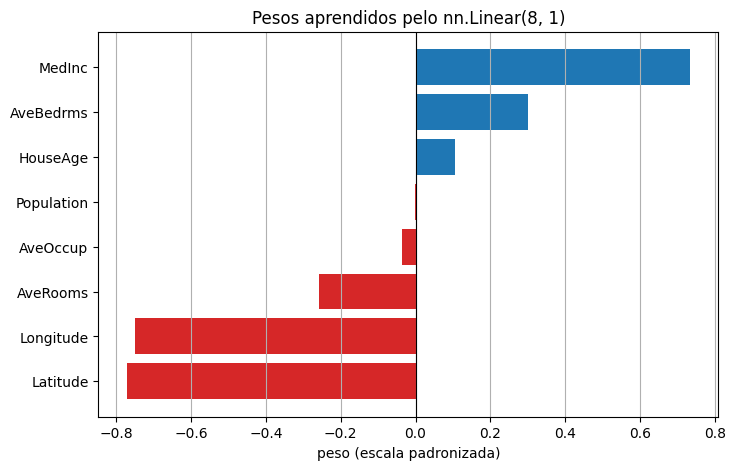

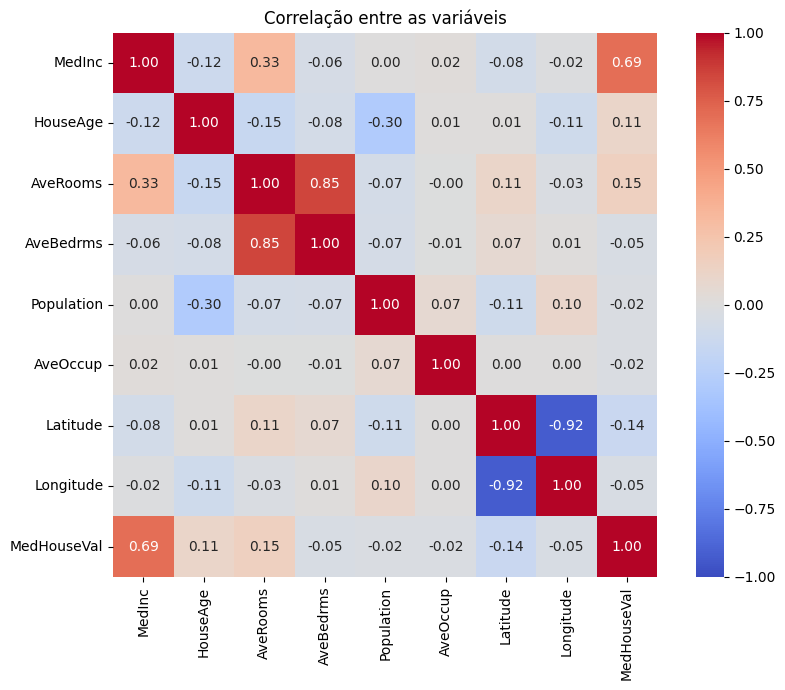

In [14]:
pesos = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns).sort_values()
print(pesos.round(3))
print('bias:', round(model.bias.item(), 4))

plt.figure(figsize=(8, 5))
cores = ['tab:red' if v < 0 else 'tab:blue' for v in pesos]
plt.barh(pesos.index, pesos.values, color=cores)
plt.axvline(0, color='k', linewidth=0.8)
plt.xlabel('peso (escala padronizada)')
plt.title('Pesos aprendidos pelo nn.Linear(8, 1)')
plt.grid(True, axis='x')
plt.show()

corr = df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlação entre as variáveis')
plt.tight_layout()
plt.show()

**Quais variáveis mais aumentam o preço previsto?** `MedInc` (renda mediana) é, com folga, a mais importante e positiva: bairros mais ricos têm casas mais caras. `AveBedrms` e `HouseAge` também têm peso positivo, mas menor.

**Quais mais diminuem?** `Latitude` e `Longitude` têm os pesos mais negativos. `AveRooms` também tem peso negativo, o que parece estranho e se explica pela correlação com `AveBedrms`. `Population` e `AveOccup` ficam perto de zero.

**Por que só podemos comparar os pesos entre si por causa da padronização?** Sem padronizar, cada peso depende da **unidade** da variável: o peso de `Population` (milhares de pessoas) e o de `MedInc` (dezenas de milhares de dólares) seriam números em escalas totalmente diferentes, e um peso pequeno poderia só refletir que a variável tem valores grandes. Depois da padronização, todas as variáveis têm média 0 e desvio padrão 1, então todos os pesos medem a mesma coisa.

## Conclusão

**O modelo é bom o suficiente?** Ele é bem melhor que o baseline, pois reduz o erro, e as curvas de treino e validação ficam próximas, sem overfitting. Mas o erro típico (RMSE) ainda é de dezenas de milhares de dólares, então ele serve como uma estimativa grosseira, não como uma previsão precisa.